<a href="https://colab.research.google.com/github/Raleese/house-price-predictor/blob/main/house_price_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error

# Loading the dataset
housing = fetch_california_housing(as_frame = True)

X = housing.data
y = housing.target

print(f"{X.columns}\n")

# separate the test set (15%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

# Then separate validation from the remaining 85%
# 15% of the original dataset is 15/85 of the remaining data
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.15 / 0.85,
    random_state=42
)

# Create the linear regression model and train it
model = LinearRegression()
model.fit(X_train, y_train)

train_pred = model.predict(X_train)
valid_pred = model.predict(X_val)

# Training metrics evaluation
train_r2 = r2_score(y_train, train_pred)
train_rmse = root_mean_squared_error(y_train, train_pred)

# Validation metrics evaluation
valid_r2 = r2_score(y_val, valid_pred)
valid_rmse = root_mean_squared_error(y_val, valid_pred)

print(f"Training R^2: {train_r2:.3f}")
print(f"Training RMSE: {train_rmse:.3f}\n")

print(f"Validation R^2: {valid_r2:.3f}")
print(f"Validation RMSE: {valid_rmse:.3f}")


Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude'],
      dtype='object')

Training R^2: 0.608
Training RMSE: 0.724

Validation R^2: 0.615
Validation RMSE: 0.718


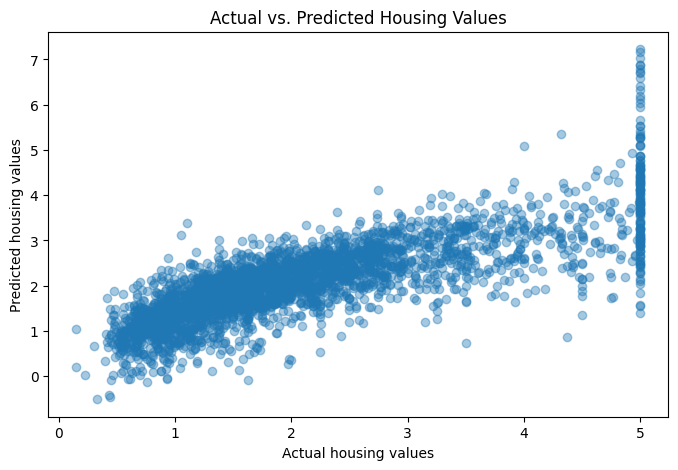

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(y_val, valid_pred, alpha=0.4)

plt.xlabel("Actual housing values")
plt.ylabel("Predicted housing values")
plt.title("Actual vs. Predicted Housing Values")

plt.show()

In [14]:
# @title Scatterplot analysis
# @markdown it's clear that housing values cap at $500 000. We can remove rows where y == 5.0, to improve model quality

--- UNCAPPED MODEL RESULTS ---
Training R^2: 0.575
Training RMSE: 0.629

Validation R^2: 0.584
Validation RMSE: 0.648


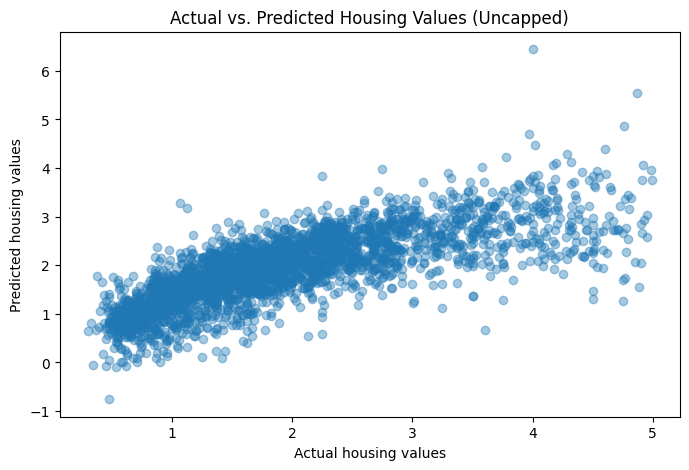

In [17]:
# Filter out housing with medium values of >= 5.0
df = housing.frame
df_filtered = df[df['MedHouseVal'] < 5.0]

X_filtered = df_filtered.drop(columns=['MedHouseVal'])
y_filtered = df_filtered['MedHouseVal']

# Split into train, validation, and test sets
X_tv, X_test_uncapped, y_tv, y_test_uncapped = train_test_split(
    X_filtered, y_filtered, test_size=0.15, random_state=42
)

X_train_u, X_val_u, y_train_u, y_val_u = train_test_split(
    X_tv, y_tv, test_size=0.15 / 0.85, random_state=42
)

# Train a new model on the uncapped data
model_uncapped = LinearRegression()
model_uncapped.fit(X_train_u, y_train_u)

# Predict & Evaluate
train_pred_u = model_uncapped.predict(X_train_u)
valid_pred_u = model_uncapped.predict(X_val_u)

print("--- UNCAPPED MODEL RESULTS ---")
print(f"Training R^2: {r2_score(y_train_u, train_pred_u):.3f}")
print(f"Training RMSE: {root_mean_squared_error(y_train_u, train_pred_u):.3f}\n")

print(f"Validation R^2: {r2_score(y_val_u, valid_pred_u):.3f}")
print(f"Validation RMSE: {root_mean_squared_error(y_val_u, valid_pred_u):.3f}")

# Plot
plt.figure(figsize=(8, 5))
plt.scatter(y_val_u, valid_pred_u, alpha=0.4)
plt.xlabel("Actual housing values")
plt.ylabel("Predicted housing values")
plt.title("Actual vs. Predicted Housing Values (Uncapped)")
plt.show()

In [18]:
# @title RMSE improved from 0.718 to 0.648
